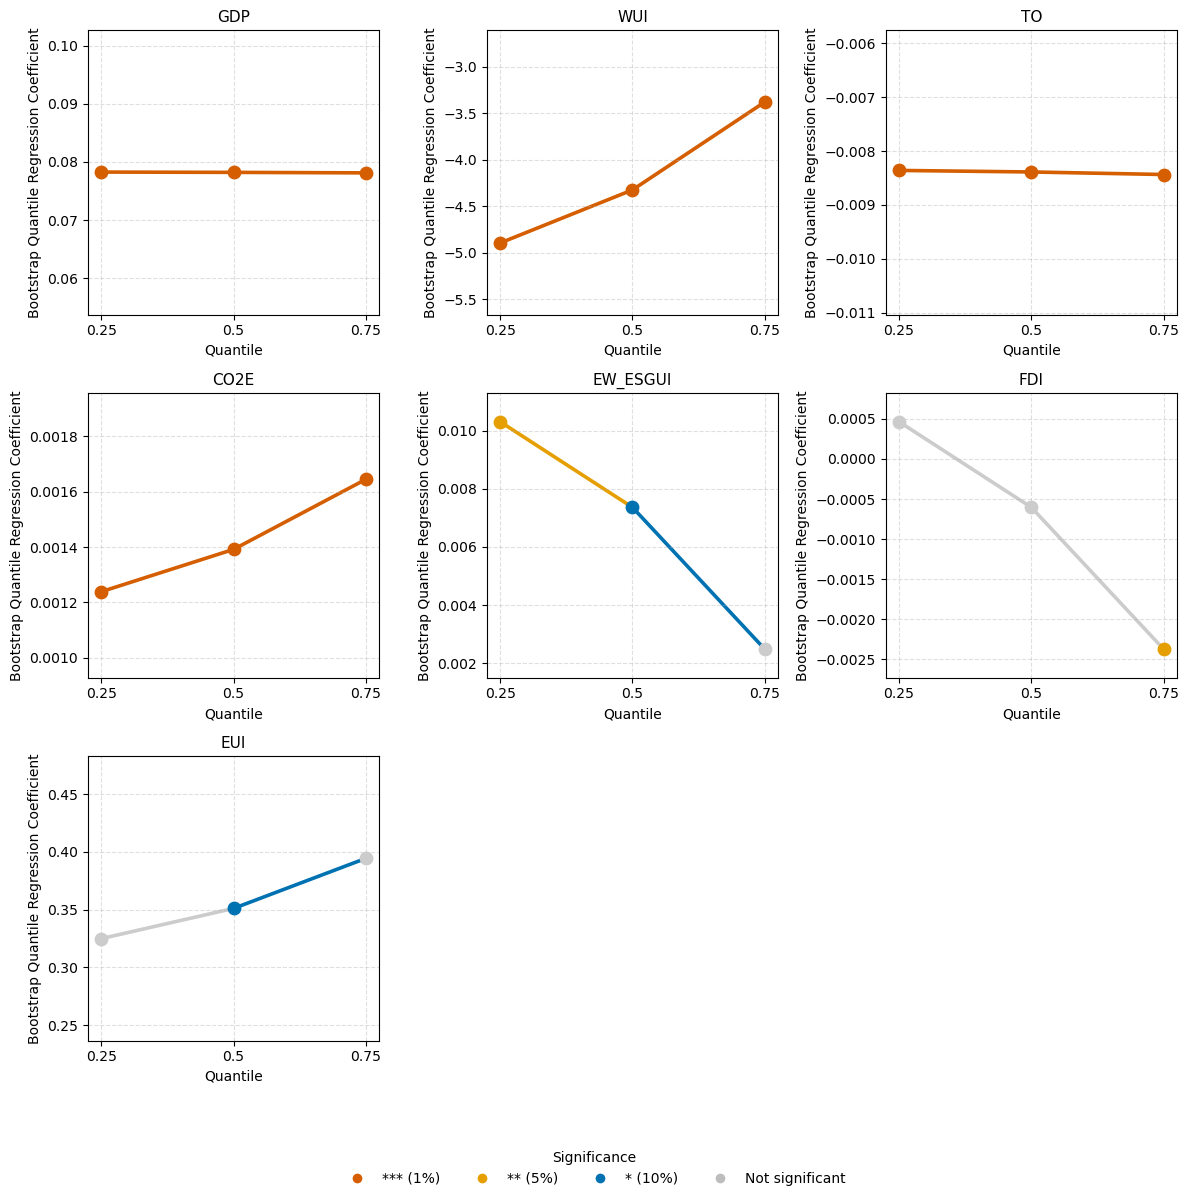

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import math

# ==============================
# 1. READ DATA
# ==============================
coef_path ="C:/Users/Khanh Quynh/Downloads/MMQR_Results_Coefficients.xlsx"
sig_path  = "C:/Users/Khanh Quynh/Downloads/mmqr222.xlsx"

df_coef = pd.read_excel(coef_path)
df_sig  = pd.read_excel(sig_path)

# ==============================
# 2. SETTINGS
# ==============================
quantiles = [0.25, 0.5, 0.75]
variables = df_coef["Variable"].tolist()

sig_color_map = {
    "***": "#D55E00",
    "**":  "#E69F00",
    "*":   "#0072B2",
    "":    "#BDBDBD",
    None:  "#BDBDBD"
}

# ==============================
# 2.1. SORT VARIABLES BY SIGNIFICANCE
# ==============================
def sig_score(sig_list):
    score_map = {"***": 3, "**": 2, "*": 1, "": 0, None: 0}
    return sum(score_map.get(s, 0) for s in sig_list)

var_scores = []

for var in variables:
    row_sig = df_sig[df_sig["Variable"] == var].iloc[0]
    sigs = [row_sig[q] for q in quantiles]
    score = sig_score(sigs)
    var_scores.append((var, score))

# sort giảm dần → biến quan trọng lên trước
var_scores_sorted = sorted(var_scores, key=lambda x: x[1], reverse=True)
variables = [v[0] for v in var_scores_sorted]

# ==============================
# 3. FIGURE LAYOUT
# ==============================
n_vars = len(variables)
n_cols = 3
n_rows = math.ceil(n_vars / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(12, 4 * n_rows))
axes = axes.flatten()

# ==============================
# 4. PLOT
# ==============================
for i, var in enumerate(variables):
    ax = axes[i]

    row_coef = df_coef[df_coef["Variable"] == var].iloc[0]
    row_sig  = df_sig[df_sig["Variable"] == var].iloc[0]

    coefs = [row_coef[q] for q in quantiles]
    sigs  = [row_sig[q]  for q in quantiles]

    # ---- line segments ----
    for j in range(len(quantiles) - 1):
        ax.plot(
            [quantiles[j], quantiles[j + 1]],
            [coefs[j], coefs[j + 1]],
            color=sig_color_map.get(sigs[j], "#cccccc"),
            linewidth=2.6,
            zorder=1
        )

    # ---- points ----
    for q, c, s in zip(quantiles, coefs, sigs):
        ax.scatter(
            q, c,
            color=sig_color_map.get(s, "#cccccc"),
            s=80,
            zorder=2
        )

    # ---- X ticks ----
    ax.set_xticks(quantiles)
    ax.set_xticklabels(["0.25", "0.5", "0.75"])

    # ---- CENTER Y ----
    valid = [c for c in coefs if pd.notna(c)]
    if valid:
        y_min, y_max = min(valid), max(valid)
        center = (y_min + y_max) / 2
        half_range = (y_max - y_min) / 2

        max_abs = max(abs(y_min), abs(y_max))
        min_half = max_abs * 0.25 if max_abs != 0 else 0.1
        half = max(half_range, min_half)

        pad = half * 0.25
        ax.set_ylim(center - half - pad, center + half + pad)

    ax.ticklabel_format(axis='y', style='plain', useOffset=False)

    ax.set_title(var, fontsize=11)
    ax.set_xlabel("Quantile")
    ax.set_ylabel("Bootstrap Quantile Regression Coefficient")
    ax.grid(True, linestyle="--", alpha=0.4)

# ==============================
# 5. REMOVE EMPTY SUBPLOTS
# ==============================
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

# ==============================
# 6. LEGEND
# ==============================
legend_elements = [
    Line2D([0], [0], marker='o', color='w',
           label="*** (1%)", markerfacecolor=sig_color_map["***"], markersize=8),
    Line2D([0], [0], marker='o', color='w',
           label="** (5%)", markerfacecolor=sig_color_map["**"], markersize=8),
    Line2D([0], [0], marker='o', color='w',
           label="* (10%)", markerfacecolor=sig_color_map["*"], markersize=8),
    Line2D([0], [0], marker='o', color='w',
           label="Not significant", markerfacecolor=sig_color_map[""], markersize=8),
]

fig.legend(
    handles=legend_elements,
    title="Significance",
    loc="lower center",
    ncol=4,
    frameon=False
)

plt.tight_layout(rect=[0, 0.08, 1, 1])
plt.show()

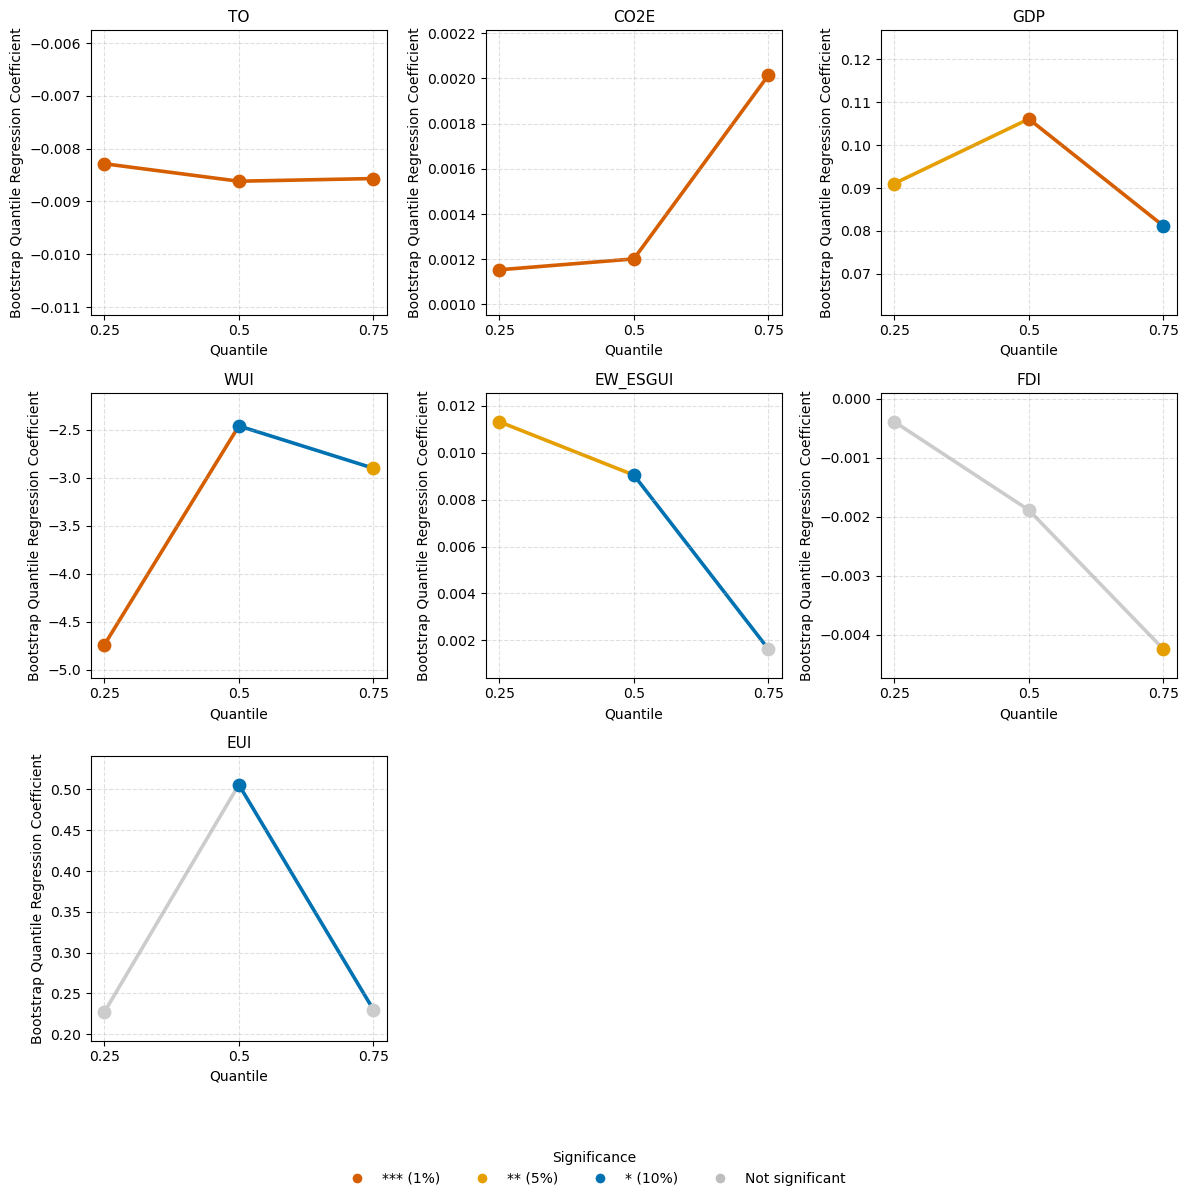

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import math

# ==============================
# 1. READ DATA
# ==============================
coef_path = "C:/Users/Khanh Quynh/Downloads/boostrap2.xlsx"
sig_path  = "C:/Users/Khanh Quynh/Downloads/Boostrap.xlsx"

df_coef = pd.read_excel(coef_path)
df_sig  = pd.read_excel(sig_path)

# ==============================
# 2. SETTINGS
# ==============================
quantiles = [0.25, 0.5, 0.75]
variables = df_coef["Variable"].tolist()

sig_color_map = {
    "***": "#D55E00",
    "**":  "#E69F00",
    "*":   "#0072B2",
    "":    "#BDBDBD",
    None:  "#BDBDBD"
}

# ==============================
# 2.1. SORT VARIABLES BY SIGNIFICANCE
# ==============================
def sig_score(sig_list):
    score_map = {"***": 3, "**": 2, "*": 1, "": 0, None: 0}
    return sum(score_map.get(s, 0) for s in sig_list)

var_scores = []

for var in variables:
    row_sig = df_sig[df_sig["Variable"] == var].iloc[0]
    sigs = [row_sig[q] for q in quantiles]
    score = sig_score(sigs)
    var_scores.append((var, score))

# sort giảm dần → biến quan trọng lên trước
var_scores_sorted = sorted(var_scores, key=lambda x: x[1], reverse=True)
variables = [v[0] for v in var_scores_sorted]

# ==============================
# 3. FIGURE LAYOUT
# ==============================
n_vars = len(variables)
n_cols = 3
n_rows = math.ceil(n_vars / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(12, 4 * n_rows))
axes = axes.flatten()

# ==============================
# 4. PLOT
# ==============================
for i, var in enumerate(variables):
    ax = axes[i]

    row_coef = df_coef[df_coef["Variable"] == var].iloc[0]
    row_sig  = df_sig[df_sig["Variable"] == var].iloc[0]

    coefs = [row_coef[q] for q in quantiles]
    sigs  = [row_sig[q]  for q in quantiles]

    # ---- line segments ----
    for j in range(len(quantiles) - 1):
        ax.plot(
            [quantiles[j], quantiles[j + 1]],
            [coefs[j], coefs[j + 1]],
            color=sig_color_map.get(sigs[j], "#cccccc"),
            linewidth=2.6,
            zorder=1
        )

    # ---- points ----
    for q, c, s in zip(quantiles, coefs, sigs):
        ax.scatter(
            q, c,
            color=sig_color_map.get(s, "#cccccc"),
            s=80,
            zorder=2
        )

    # ---- X ticks ----
    ax.set_xticks(quantiles)
    ax.set_xticklabels(["0.25", "0.5", "0.75"])

    # ---- CENTER Y ----
    valid = [c for c in coefs if pd.notna(c)]
    if valid:
        y_min, y_max = min(valid), max(valid)
        center = (y_min + y_max) / 2
        half_range = (y_max - y_min) / 2

        max_abs = max(abs(y_min), abs(y_max))
        min_half = max_abs * 0.25 if max_abs != 0 else 0.1
        half = max(half_range, min_half)

        pad = half * 0.25
        ax.set_ylim(center - half - pad, center + half + pad)

    ax.ticklabel_format(axis='y', style='plain', useOffset=False)

    ax.set_title(var, fontsize=11)
    ax.set_xlabel("Quantile")
    ax.set_ylabel("Bootstrap Quantile Regression Coefficient")
    ax.grid(True, linestyle="--", alpha=0.4)

# ==============================
# 5. REMOVE EMPTY SUBPLOTS
# ==============================
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

# ==============================
# 6. LEGEND
# ==============================
legend_elements = [
    Line2D([0], [0], marker='o', color='w',
           label="*** (1%)", markerfacecolor=sig_color_map["***"], markersize=8),
    Line2D([0], [0], marker='o', color='w',
           label="** (5%)", markerfacecolor=sig_color_map["**"], markersize=8),
    Line2D([0], [0], marker='o', color='w',
           label="* (10%)", markerfacecolor=sig_color_map["*"], markersize=8),
    Line2D([0], [0], marker='o', color='w',
           label="Not significant", markerfacecolor=sig_color_map[""], markersize=8),
]

fig.legend(
    handles=legend_elements,
    title="Significance",
    loc="lower center",
    ncol=4,
    frameon=False
)

plt.tight_layout(rect=[0, 0.08, 1, 1])
plt.show()